# Users

## Caricamento dati Users

In [1]:
import pandas as pd

In [2]:
fp = r"..\01_dati_originali\users_edit.csv"

df_users = pd.read_csv(fp)

df_users.head()

,UserID,Gender,Age,CAP,Work
0,1,F,11,20023,Studente
1,2,M,13,72022,Studente
2,3,M,24,36100,Autista
3,4,M,37,85024,Data Engineer
4,5,M,15,1010,Studente


## Controllo Nan e duplicati

In [3]:
df_users.isna().sum()

UserID    0
Gender    0
Age       0
CAP       0
Work      0
dtype: int64

In [4]:
df_users_no_dup = df_users.drop_duplicates()

df_users.shape[0],df_users_no_dup.shape[0]

(6040, 6040)

## Sanity check valori

In [5]:
df_users["Work"].value_counts()

Work
Studente         1093
Data Analyst      630
Disoccupato       609
Data Engineer     585
Dirigente         444
Programmatore     420
Avvocato          323
Ingegnere         258
Impiegato         238
Operaio           233
Attore            203
Ricercatore       192
Direttore         151
Autista           127
Architetto        121
Infermiere        103
Insegnante         95
Data Scientis      81
Musicista          62
Atleta             60
Dottore            12
Name: count, dtype: int64

In [6]:
df_users["Gender"].value_counts()

Gender
M    4331
F    1709
Name: count, dtype: int64

<Axes: >

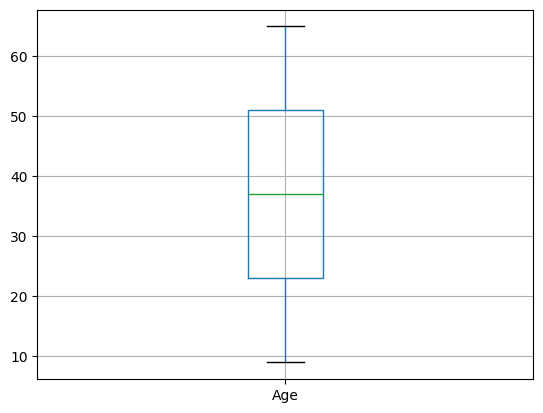

In [7]:
df_users.boxplot(column="Age")


## Aggiunta colonna fascia eta

In [8]:
# Fascia d'età
df_users['AgeGroup'] = pd.cut(
    df_users['Age'],
    bins=[0, 18, 25, 35, 45, 55, float('inf')],
    labels=['U18', '18-24', '25-34', '35-44', '45-54', '55+'],
    right=False,          # intervalli [18, 25): 18 incluso, 25 escluso
)

df_users.groupby('AgeGroup', observed=True)['Age'].agg(['min', 'max', 'count'])


,min,max,count
AgeGroup,,,
U18,9,17,924
18-24,18,24,716
25-34,25,34,1054
35-44,35,44,1104
45-54,45,54,1076
55+,55,65,1166


## Salvataggio csv users

In [9]:
fp = r"..\03_dati_preprocessati\users_checked.csv"

df_users.to_csv(fp)

# Ratings

In [10]:
fp = r"..\01_dati_originali\ratings_edit.csv"

df_ratings = pd.read_csv(fp)

df_ratings.head()

,UserID,MovieID,Rating,Timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


## Conversione Timestamp

In [11]:
df_ratings['Timestamp'] = pd.to_datetime(df_ratings['Timestamp'], unit='s')

df_ratings.head()

,UserID,MovieID,Rating,Timestamp
0,1,1193,5,2000-12-31 22:12:40
1,1,661,3,2000-12-31 22:35:09
2,1,914,3,2000-12-31 22:32:48
3,1,3408,4,2000-12-31 22:04:35
4,1,2355,5,2001-01-06 23:38:11


In [12]:
df_ratings.tail()

,UserID,MovieID,Rating,Timestamp
1000204,6040,1091,1,2000-04-26 02:35:41
1000205,6040,1094,5,2000-04-25 23:21:27
1000206,6040,562,5,2000-04-25 23:19:06
1000207,6040,1096,4,2000-04-26 02:20:48
1000208,6040,1097,4,2000-04-26 02:19:29


## Controllo duplicati e nan

In [13]:
df_ratings.isna().sum()

UserID       0
MovieID      0
Rating       0
Timestamp    0
dtype: int64

In [14]:
df_ratings_no_dup = df_ratings.drop_duplicates()

df_ratings.shape[0], df_ratings_no_dup.shape[0]

(1000209, 1000209)

## Salvaggio csv ratings

In [15]:
fp = r"..\03_dati_preprocessati\ratings_checked.csv"

df_ratings.to_csv(fp)

## Esempio queries

Film con piu recensioni

In [16]:
df_ratings.groupby(by='MovieID')['UserID'].count()\
         .sort_values(ascending = False)\
         .head(10)

MovieID
2858    3428
260     2991
1196    2990
1210    2883
480     2672
2028    2653
589     2649
2571    2590
1270    2583
593     2578
Name: UserID, dtype: int64